In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset directly from the raw folder
df = pd.read_csv('../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv')

# Show the first 5 rows
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 1. Target Distribution and Missing Values
Before building a model, we must check the balance of our target variable (Attrition). If only 2% of employees leave, the model will just predict "No" for everyone and be 98% accurate but completely useless.

Total missing values in dataset: 0

--- Attrition Counts ---
Attrition
0    1233
1     237
Name: count, dtype: int64

--- Attrition Percentage ---
Attrition
0    83.88%
1    16.12%
Name: proportion, dtype: str


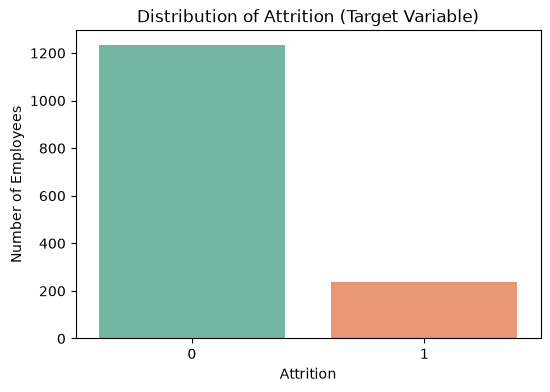

In [4]:
# 1. Check for missing values in the entire dataset
total_missing = df.isnull().sum().sum()
print(f"Total missing values in dataset: {total_missing}")

# 2. Check class imbalance
attrition_counts = df['Attrition'].value_counts()
attrition_pct = df['Attrition'].value_counts(normalize=True) * 100

print("\n--- Attrition Counts ---")
print(attrition_counts)
print("\n--- Attrition Percentage ---")
print(attrition_pct.round(2).astype(str) + '%')

# 3. Visualize the class imbalance
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Attrition', hue='Attrition', palette='Set2', legend=False)
plt.title('Distribution of Attrition (Target Variable)')
plt.ylabel('Number of Employees')
plt.show()

## 2. Digging Deeper: Burnout and Pay

We know about 16% of our people leave. But what drives them away? A common HR hypothesis is burnout (working too much overtime) and compensation (monthly income). 

Let's plot these against our target to see if the data actually supports these theories.

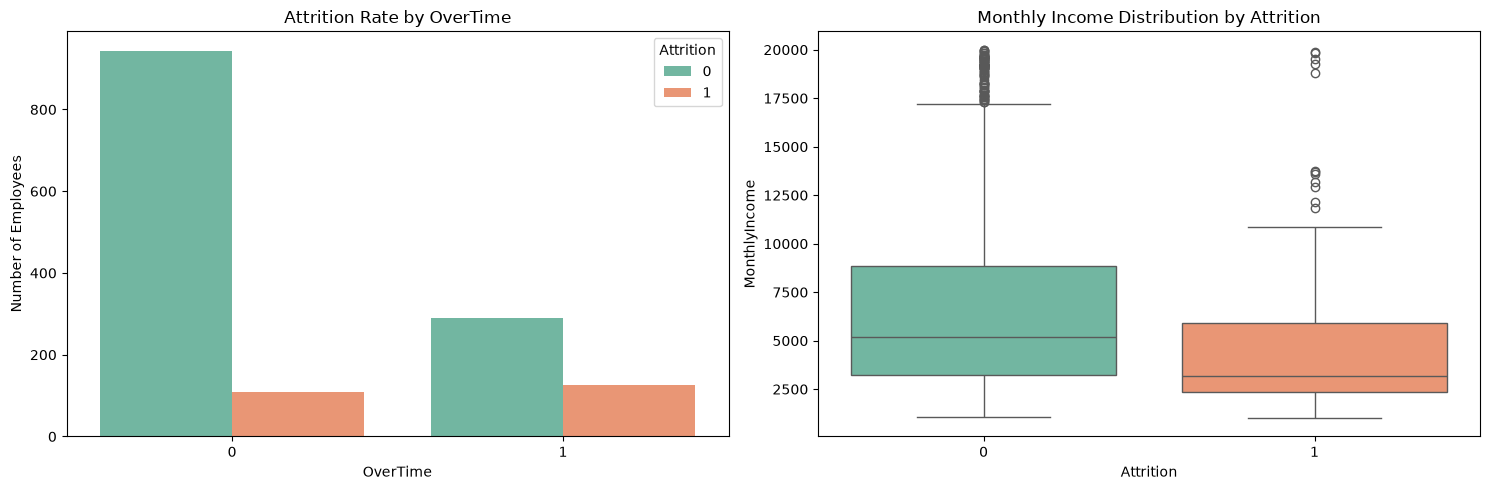

In [5]:
# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: OverTime vs Attrition
sns.countplot(data=df, x='OverTime', hue='Attrition', palette='Set2', ax=axes[0])
axes[0].set_title('Attrition Rate by OverTime')
axes[0].set_ylabel('Number of Employees')

# Plot 2: MonthlyIncome vs Attrition
sns.boxplot(data=df, x='Attrition', y='MonthlyIncome', hue='Attrition', palette='Set2', ax=axes[1], legend=False)
axes[1].set_title('Monthly Income Distribution by Attrition')

plt.tight_layout()
plt.show()

## 3. Key EDA Takeaways

Before moving to baseline model, here is the summary of findings from the visual analysis:

1. **Class Imbalance:** Only 16.12% of employees in this dataset left the company. If we just predict "No" for everyone, we get 83.88% accuracy but 0% usefulness. We must use techniques like `class_weight='balanced'` and rely on metrics like F1-score and Average Precision (AP), not just accuracy.
2. **Burnout is Real:** Employees working OverTime have a dramatically higher rate of attrition. 
3. **Pay Matters:** Employees who left generally had lower median monthly incomes.
4. **No Missing Values:** The dataset is exceptionally clean, so imputation won't be a primary concern, but our pipeline handles it just in case.